# Fashion Sales & Customer Market Intelligence

## Introduction
This project analyzes 5,000 simulated fashion sales records to understand sales trends, customer behavior, and product performance.

## Objectives
- Identify top-selling products and categories.
- Analyze monthly and seasonal sales.
- Compare online and physical store revenue.
- Provide business recommendations.

## Tools Used
Python, Pandas, Matplotlib, Seaborn, and Jupyter Notebook.

In [1]:
import pandas as pd

dataset = pd.read_csv("fashion_sales.csv")
dataset.head()
#dataset.shape
#dataset.columns
#dataset.dtypes
#dataset.isnull().sum()
#dataset.duplicated().sum()

,order_id,customer_id,order_date,product_id,product_name,category,gender,size,color,quantity,unit_price,discount,sales_channel,region,payment_method
0,ORD00001,CUST0814,2024-04-10,P004,Hoodie,Clothing,Unisex,L,Grey,3,25000,0.15,Physical Store,Lagos,Cash
1,ORD00001,CUST0814,2024-04-10,P021,Silk Scarf,Accessories,Women,One Size,Blue,1,15500,0.10,Physical Store,Lagos,Cash
2,ORD00002,CUST1318,2025-05-25,P022,Sports Socks,Accessories,Unisex,M,Grey,1,4500,0.10,Online,Port Harcourt,Bank Transfer
3,ORD00003,CUST0551,2025-12-07,P001,Cotton T-Shirt,Clothing,Unisex,L,White,1,8500,0.15,Physical Store,Abuja,Bank Transfer
4,ORD00004,CUST1230,2025-09-25,P016,Leather Belt,Accessories,Unisex,L,Black,2,11000,0.10,Online,Lagos,Bank Transfer


Data Understanding !

In [2]:
dataset.shape

(5000, 15)

In [3]:
dataset.columns

Index(['order_id', 'customer_id', 'order_date', 'product_id', 'product_name',
       'category', 'gender', 'size', 'color', 'quantity', 'unit_price',
       'discount', 'sales_channel', 'region', 'payment_method'],
      dtype='str')

In [4]:
dataset.dtypes

order_id              str
customer_id           str
order_date            str
product_id            str
product_name          str
category              str
gender                str
size                  str
color                 str
quantity            int64
unit_price          int64
discount          float64
sales_channel         str
region                str
payment_method        str
dtype: object

In [5]:
dataset.isnull().sum()

order_id           0
customer_id        0
order_date         0
product_id         0
product_name       0
category           0
gender             0
size              12
color              9
quantity           0
unit_price         0
discount           0
sales_channel      0
region             7
payment_method     0
dtype: int64

In [6]:
dataset.duplicated().sum()

np.int64(0)

In [7]:
dataset["customer_id"].nunique()

1392

In [8]:
dataset["product_id"].nunique()

24

In [9]:
dataset["category"].nunique()

3

In [10]:
dataset["region"].nunique()

6

In [11]:
dataset["sales_channel"].nunique()

2

In [12]:
dataset["payment_method"].nunique()

5

In [13]:
dataset["order_date"].min()

'2024-01-01'

In [14]:
dataset["order_date"].max()

'2025-12-31'

In [15]:
dataset["order_id"].nunique()

3973

Data Cleaning !

In [16]:
dataset["order_date"] = pd.to_datetime(dataset["order_date"])

In [17]:
dataset["order_date"].dtype

dtype('<M8[us]')

In [18]:
dataset[dataset["size"].isnull()]

,order_id,customer_id,order_date,product_id,product_name,category,gender,size,color,quantity,unit_price,discount,sales_channel,region,payment_method
162,ORD00124,CUST0042,2025-07-16,P006,Blazer,Clothing,Women,NaN,Black,1,48000,0.00,Online,Lagos,Card
324,ORD00251,CUST1249,2025-09-07,P004,Hoodie,Clothing,Unisex,NaN,Green,1,25000,0.00,Physical Store,Enugu,Card
1602,ORD01260,CUST1096,2024-06-20,P011,Canvas Trainers,Footwear,Unisex,NaN,White,2,29500,0.15,Physical Store,Abuja,POS
2643,ORD02101,CUST0385,2025-01-29,P001,Cotton T-Shirt,Clothing,Unisex,NaN,Black,1,8500,0.00,Online,Port Harcourt,Card
3556,ORD02828,CUST0021,2024-12-16,P001,Cotton T-Shirt,Clothing,Unisex,NaN,White,1,8500,0.00,Online,Ibadan,Mobile Wallet
3586,ORD02854,CUST0289,2024-12-18,P014,Flip Flops,Footwear,Unisex,NaN,Blue,1,6500,0.25,Physical Store,Port Harcourt,POS
4176,ORD03317,CUST1309,2025-09-03,P007,Joggers,Clothing,Unisex,NaN,Navy,2,17500,0.15,Online,Lagos,Card
4235,ORD03364,CUST1396,2025-12-08,P017,Sunglasses,Accessories,Unisex,NaN,Brown,3,14000,0.00,Online,Lagos,Bank Transfer
4378,ORD03482,CUST0323,2025-12-28,P015,Crossbody Bag,Accessories,Women,NaN,Black,3,19500,0.30,Physical Store,Kano,POS
4494,ORD03570,CUST0637,2025-05-19,P009,Running Sneakers,Footwear,Unisex,NaN,White,1,42000,0.00,Online,Lagos,Card


In [19]:
dataset["size"].unique()

<ArrowStringArray>
[       'L', 'One Size',        'M',       '38',       '42',       '39',
       '43',       '40',        'S',       'XL',       '41',       '37',
        nan,       '44']
Length: 14, dtype: str

In [20]:
dataset["size"].isnull().sum()

np.int64(12)

In [21]:
dataset["size"].value_counts(dropna=False)

size
One Size    1137
L            785
M            726
S            694
XL           387
40           235
38           204
41           201
39           199
42           163
43           120
37            93
44            44
NaN           12
Name: count, dtype: int64

In [22]:
dataset.groupby("product_name")["size"].unique()

product_name
Ankle Boots                      [39, 37, 38, 40, 41]
Baseball Cap                               [One Size]
Blazer                                 [nan, S, L, M]
Canvas Trainers         [39, 43, 40, 42, 41, 38, nan]
Cotton T-Shirt                     [L, XL, S, M, nan]
Crossbody Bag                         [One Size, nan]
Denim Jeans                             [L, XL, S, M]
Evening Gown                                [L, M, S]
Flip Flops              [39, 43, 38, 41, 40, 42, nan]
Formal Loafers                   [43, 42, 40, 44, 41]
Hoodie                                [L, XL, M, nan]
Joggers                            [M, L, XL, S, nan]
Knit Sweater                                [M, L, S]
Leather Belt                                [L, S, M]
Leather Sandals                  [38, 40, 39, 41, 37]
Linen Shirt                             [S, XL, L, M]
Rain Jacket                             [L, S, M, XL]
Running Sneakers    [42, 43, 41, 38, 44, 39, 40, nan]
Silk Scarf     

In [23]:
dataset["size"] = dataset["size"].fillna("Unknown")

In [24]:
dataset["size"].isnull().sum()

np.int64(0)

In [26]:
dataset[dataset["color"].isnull()]

,order_id,customer_id,order_date,product_id,product_name,category,gender,size,color,quantity,unit_price,discount,sales_channel,region,payment_method
136,ORD00103,CUST0235,2025-09-15,P019,Tote Bag,Accessories,Unisex,One Size,NaN,1,12500,0.2,Online,Lagos,Card
263,ORD00205,CUST0229,2024-03-18,P010,Leather Sandals,Footwear,Women,41,NaN,5,18500,0.3,Online,Lagos,Card
333,ORD00260,CUST0010,2024-05-10,P009,Running Sneakers,Footwear,Unisex,38,NaN,1,42000,0.0,Online,Abuja,Mobile Wallet
724,ORD00563,CUST0254,2024-01-14,P016,Leather Belt,Accessories,Unisex,M,NaN,3,11000,0.3,Physical Store,Lagos,POS
1465,ORD01148,CUST0856,2024-04-24,P024,Evening Gown,Clothing,Women,S,NaN,2,78000,0.0,Online,Abuja,Mobile Wallet
2189,ORD01740,CUST0847,2024-09-02,P003,Summer Dress,Clothing,Women,S,NaN,3,28000,0.0,Online,Enugu,Mobile Wallet
2452,ORD01943,CUST1130,2024-05-06,P024,Evening Gown,Clothing,Women,L,NaN,1,78000,0.2,Physical Store,Ibadan,POS
3298,ORD02620,CUST0768,2025-09-11,P021,Silk Scarf,Accessories,Women,One Size,NaN,1,15500,0.1,Physical Store,Lagos,POS
3371,ORD02682,CUST0870,2024-04-09,P010,Leather Sandals,Footwear,Women,40,NaN,2,18500,0.0,Online,Port Harcourt,Bank Transfer


In [27]:
dataset["color"] = dataset["color"].fillna("Unknown")

In [28]:
dataset["color"].isnull().sum()

np.int64(0)

In [30]:
dataset[dataset["region"].isnull()]

,order_id,customer_id,order_date,product_id,product_name,category,gender,size,color,quantity,unit_price,discount,sales_channel,region,payment_method
330,ORD00257,CUST1154,2024-08-14,P022,Sports Socks,Accessories,Unisex,M,Grey,1,4500,0.10,Online,NaN,Bank Transfer
761,ORD00593,CUST1325,2025-01-22,P001,Cotton T-Shirt,Clothing,Unisex,S,Black,2,8500,0.15,Physical Store,NaN,Bank Transfer
774,ORD00603,CUST0067,2025-08-25,P001,Cotton T-Shirt,Clothing,Unisex,M,Black,1,8500,0.15,Physical Store,NaN,POS
1273,ORD00999,CUST1217,2025-06-08,P001,Cotton T-Shirt,Clothing,Unisex,XL,Navy,2,8500,0.25,Physical Store,NaN,Card
1521,ORD01192,CUST0201,2024-04-17,P008,Knit Sweater,Clothing,Women,S,Green,2,23000,0.05,Physical Store,NaN,POS
2120,ORD01683,CUST0178,2024-10-03,P005,Linen Shirt,Clothing,Men,M,Beige,2,18500,0.10,Online,NaN,Mobile Wallet
4246,ORD03371,CUST1267,2025-02-26,P015,Crossbody Bag,Accessories,Women,One Size,Black,1,19500,0.00,Online,NaN,Card


In [31]:
dataset["region"] = dataset["region"].fillna("Unknown")

In [32]:
dataset["region"].isnull().sum()

np.int64(0)

In [33]:
dataset.isnull().sum()

order_id          0
customer_id       0
order_date        0
product_id        0
product_name      0
category          0
gender            0
size              0
color             0
quantity          0
unit_price        0
discount          0
sales_channel     0
region            0
payment_method    0
dtype: int64

In [34]:
dataset[dataset["quantity"] <= 0]

,order_id,customer_id,order_date,product_id,product_name,category,gender,size,color,quantity,unit_price,discount,sales_channel,region,payment_method


In [35]:
dataset[dataset["unit_price"] <= 0]

,order_id,customer_id,order_date,product_id,product_name,category,gender,size,color,quantity,unit_price,discount,sales_channel,region,payment_method


In [36]:
dataset[(dataset["discount"] < 0) | (dataset["discount"] > 1)]

,order_id,customer_id,order_date,product_id,product_name,category,gender,size,color,quantity,unit_price,discount,sales_channel,region,payment_method


In [37]:
dataset["category"].unique()

<ArrowStringArray>
['Clothing', 'Accessories', 'Footwear']
Length: 3, dtype: str

In [38]:
dataset["product_name"].unique()

<ArrowStringArray>
[          'Hoodie',       'Silk Scarf',     'Sports Socks',
   'Cotton T-Shirt',     'Leather Belt',  'Leather Sandals',
         'Tote Bag',       'Sunglasses',     'Summer Dress',
 'Running Sneakers',      'Rain Jacket',       'Flip Flops',
      'Wrist Watch',    'Crossbody Bag',     'Baseball Cap',
      'Linen Shirt',          'Joggers',   'Formal Loafers',
     'Evening Gown',      'Denim Jeans',  'Canvas Trainers',
      'Ankle Boots',     'Knit Sweater',           'Blazer']
Length: 24, dtype: str

In [39]:
dataset.groupby("product_name")["category"].unique()

product_name
Ankle Boots            [Footwear]
Baseball Cap        [Accessories]
Blazer                 [Clothing]
Canvas Trainers        [Footwear]
Cotton T-Shirt         [Clothing]
Crossbody Bag       [Accessories]
Denim Jeans            [Clothing]
Evening Gown           [Clothing]
Flip Flops             [Footwear]
Formal Loafers         [Footwear]
Hoodie                 [Clothing]
Joggers                [Clothing]
Knit Sweater           [Clothing]
Leather Belt        [Accessories]
Leather Sandals        [Footwear]
Linen Shirt            [Clothing]
Rain Jacket            [Clothing]
Running Sneakers       [Footwear]
Silk Scarf          [Accessories]
Sports Socks        [Accessories]
Summer Dress           [Clothing]
Sunglasses          [Accessories]
Tote Bag            [Accessories]
Wrist Watch         [Accessories]
Name: category, dtype: object

In [40]:
dataset[["quantity", "unit_price", "discount"]].describe()

,quantity,unit_price,discount
count,5000.000000,5000.000000,5000.000000
mean,1.571800,22718.900000,0.082430
std,0.902113,15488.192587,0.087443
min,1.000000,4500.000000,0.000000
25%,1.000000,11000.000000,0.000000
50%,1.000000,18500.000000,0.050000
75%,2.000000,28000.000000,0.150000
max,5.000000,78000.000000,0.300000


In [41]:
dataset[dataset["unit_price"] > 50000]

,order_id,customer_id,order_date,product_id,product_name,category,gender,size,color,quantity,unit_price,discount,sales_channel,region,payment_method
30,ORD00023,CUST0701,2024-08-17,P013,Formal Loafers,Footwear,Men,43,Brown,2,51000,0.00,Online,Ibadan,Bank Transfer
36,ORD00028,CUST0045,2024-12-22,P024,Evening Gown,Clothing,Women,L,Black,2,78000,0.25,Online,Port Harcourt,Card
59,ORD00045,CUST1206,2024-09-23,P012,Ankle Boots,Footwear,Women,39,Black,1,56000,0.10,Physical Store,Lagos,Card
68,ORD00051,CUST1022,2025-02-24,P012,Ankle Boots,Footwear,Women,37,Black,1,56000,0.10,Physical Store,Abuja,Cash
84,ORD00065,CUST0014,2024-06-29,P012,Ankle Boots,Footwear,Women,38,Black,1,56000,0.15,Online,Lagos,Bank Transfer
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4929,ORD03920,CUST1220,2025-02-03,P013,Formal Loafers,Footwear,Men,43,Black,1,51000,0.00,Online,Abuja,Bank Transfer
4948,ORD03935,CUST1220,2024-10-06,P013,Formal Loafers,Footwear,Men,42,Black,1,51000,0.10,Online,Abuja,Mobile Wallet
4978,ORD03956,CUST1065,2025-07-09,P012,Ankle Boots,Footwear,Women,37,Brown,1,56000,0.10,Online,Port Harcourt,Bank Transfer
4993,ORD03968,CUST1491,2025-08-10,P024,Evening Gown,Clothing,Women,S,Black,1,78000,0.10,Online,Lagos,Card


In [42]:
dataset[dataset["quantity"] > 3]

,order_id,customer_id,order_date,product_id,product_name,category,gender,size,color,quantity,unit_price,discount,sales_channel,region,payment_method
79,ORD00061,CUST1113,2024-02-24,P010,Leather Sandals,Footwear,Women,41,Black,4,18500,0.00,Physical Store,Ibadan,Cash
81,ORD00063,CUST0699,2025-03-07,P022,Sports Socks,Accessories,Unisex,M,Grey,4,4500,0.00,Online,Lagos,Card
119,ORD00091,CUST0148,2024-11-18,P002,Denim Jeans,Clothing,Unisex,M,Blue,4,22500,0.20,Physical Store,Lagos,Bank Transfer
150,ORD00114,CUST0605,2025-11-15,P010,Leather Sandals,Footwear,Women,41,Black,5,18500,0.00,Physical Store,Abuja,Cash
154,ORD00117,CUST0960,2025-10-09,P005,Linen Shirt,Clothing,Men,XL,White,5,18500,0.10,Online,Lagos,Mobile Wallet
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4916,ORD03907,CUST0081,2025-12-05,P007,Joggers,Clothing,Unisex,S,Black,4,17500,0.00,Physical Store,Lagos,Bank Transfer
4924,ORD03915,CUST0858,2025-01-09,P010,Leather Sandals,Footwear,Women,41,Tan,4,18500,0.05,Online,Ibadan,Card
4947,ORD03934,CUST0580,2024-11-01,P010,Leather Sandals,Footwear,Women,40,Tan,4,18500,0.05,Physical Store,Enugu,Bank Transfer
4983,ORD03960,CUST0872,2024-08-30,P001,Cotton T-Shirt,Clothing,Unisex,XL,Black,4,8500,0.20,Physical Store,Port Harcourt,Bank Transfer


In [43]:
dataset["sales_channel"].unique()

<ArrowStringArray>
['Physical Store', 'Online']
Length: 2, dtype: str

In [44]:
dataset["payment_method"].unique()

<ArrowStringArray>
['Cash', 'Bank Transfer', 'Card', 'Mobile Wallet', 'POS']
Length: 5, dtype: str

In [45]:
dataset.to_csv("cleaned_fashion_sales.csv", index=False)

In [46]:
original = pd.read_csv("fashion_sales.csv")
cleaned = pd.read_csv("cleaned_fashion_sales.csv")

print("Original missing:", original.isnull().sum().sum())
print("Cleaned missing:", cleaned.isnull().sum().sum())

Original missing: 28
Cleaned missing: 0


FEATURE ENGINEERING

In [48]:
dataset["gross_sales"] = dataset["quantity"] * dataset["unit_price"]

dataset.head()

,order_id,customer_id,order_date,product_id,product_name,category,gender,size,color,quantity,unit_price,discount,sales_channel,region,payment_method,gross_sales
0,ORD00001,CUST0814,2024-04-10,P004,Hoodie,Clothing,Unisex,L,Grey,3,25000,0.15,Physical Store,Lagos,Cash,75000
1,ORD00001,CUST0814,2024-04-10,P021,Silk Scarf,Accessories,Women,One Size,Blue,1,15500,0.10,Physical Store,Lagos,Cash,15500
2,ORD00002,CUST1318,2025-05-25,P022,Sports Socks,Accessories,Unisex,M,Grey,1,4500,0.10,Online,Port Harcourt,Bank Transfer,4500
3,ORD00003,CUST0551,2025-12-07,P001,Cotton T-Shirt,Clothing,Unisex,L,White,1,8500,0.15,Physical Store,Abuja,Bank Transfer,8500
4,ORD00004,CUST1230,2025-09-25,P016,Leather Belt,Accessories,Unisex,L,Black,2,11000,0.10,Online,Lagos,Bank Transfer,22000


In [49]:
dataset[["quantity", "unit_price", "gross_sales"]].head()

,quantity,unit_price,gross_sales
0,3,25000,75000
1,1,15500,15500
2,1,4500,4500
3,1,8500,8500
4,2,11000,22000


In [50]:
dataset["discount_amount"] = dataset["gross_sales"] * dataset["discount"]

In [51]:
dataset["net_sales"] = dataset["gross_sales"] - dataset["discount_amount"]

In [52]:
dataset[["gross_sales", "discount_amount", "net_sales"]].head()

,gross_sales,discount_amount,net_sales
0,75000,11250.0,63750.0
1,15500,1550.0,13950.0
2,4500,450.0,4050.0
3,8500,1275.0,7225.0
4,22000,2200.0,19800.0


In [53]:
dataset["month"] = dataset["order_date"].dt.month

In [54]:
dataset[["order_date", "month"]].head()

,order_date,month
0,2024-04-10,4
1,2024-04-10,4
2,2025-05-25,5
3,2025-12-07,12
4,2025-09-25,9


In [55]:
dataset["month_name"] = dataset["order_date"].dt.month_name()

In [56]:
dataset[["order_date", "month", "month_name"]].head()

,order_date,month,month_name
0,2024-04-10,4,April
1,2024-04-10,4,April
2,2025-05-25,5,May
3,2025-12-07,12,December
4,2025-09-25,9,September


In [57]:
dataset["quarter"] = dataset["order_date"].dt.quarter

In [58]:
dataset[["order_date", "quarter"]].head()

,order_date,quarter
0,2024-04-10,2
1,2024-04-10,2
2,2025-05-25,2
3,2025-12-07,4
4,2025-09-25,3


In [59]:
dataset["season"] = dataset["month"].apply(
    lambda x: "Dry" if x in [11, 12, 1, 2, 3] else "Rainy"
)

In [60]:
dataset[["month_name", "season"]].head()

,month_name,season
0,April,Rainy
1,April,Rainy
2,May,Rainy
3,December,Dry
4,September,Rainy


In [61]:
average_order_value = dataset["net_sales"].sum() / dataset["order_id"].nunique()

print(round(average_order_value, 2))

41179.1


In [63]:
dataset.to_csv("fashion_sales_final.csv", index=False)

Exploratory Data Analysis (EDA)!

In [64]:
# Which product category generates the highest revenue?


dataset.groupby("category")["net_sales"].sum()

category
Accessories    33567225.0
Clothing       75985050.0
Footwear       54052300.0
Name: net_sales, dtype: float64

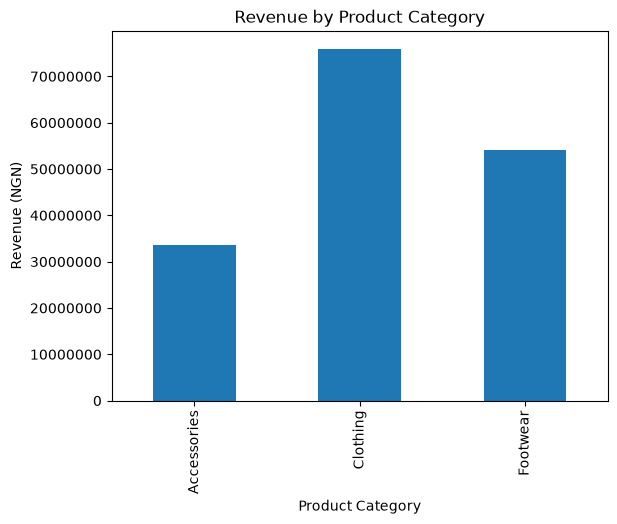

In [67]:
# bar chart showing revenue by product category.

import matplotlib.pyplot as plt

dataset.groupby("category")["net_sales"].sum().plot(kind="bar")

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue (NGN)")
plt.ticklabel_format(style="plain", axis="y")
plt.show()

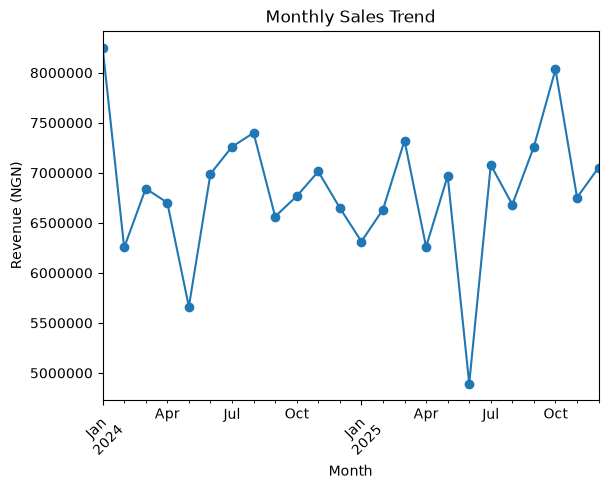

In [68]:
# Which months generate the highest sales?


monthly = dataset.groupby(dataset["order_date"].dt.to_period("M"))["net_sales"].sum()

monthly.plot(kind="line", marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (NGN)")
plt.xticks(rotation=45)
plt.ticklabel_format(style="plain", axis="y")
plt.show()

In [69]:
# Which season generates the highest revenue?


dataset.groupby("season")["net_sales"].sum()

season
Dry      69084775.0
Rainy    94519800.0
Name: net_sales, dtype: float64

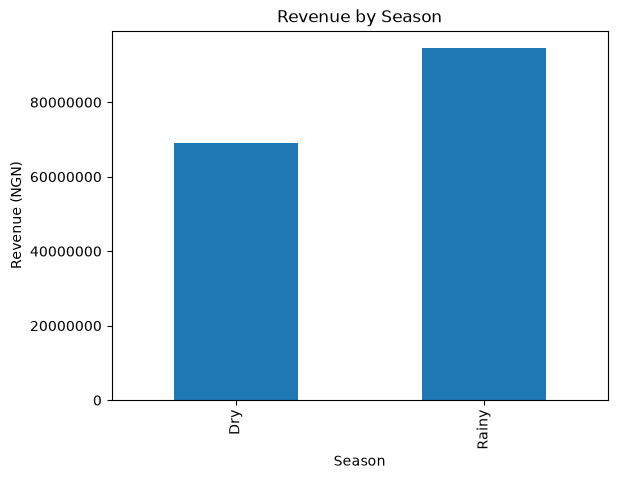

In [70]:
dataset.groupby("season")["net_sales"].sum().plot(kind="bar")

plt.title("Revenue by Season")
plt.xlabel("Season")
plt.ylabel("Revenue (NGN)")
plt.ticklabel_format(style="plain", axis="y")
plt.show()

In [71]:
# Which sales channel generates the highest revenue?



dataset.groupby("sales_channel")["net_sales"].sum()

sales_channel
Online            90396500.0
Physical Store    73208075.0
Name: net_sales, dtype: float64

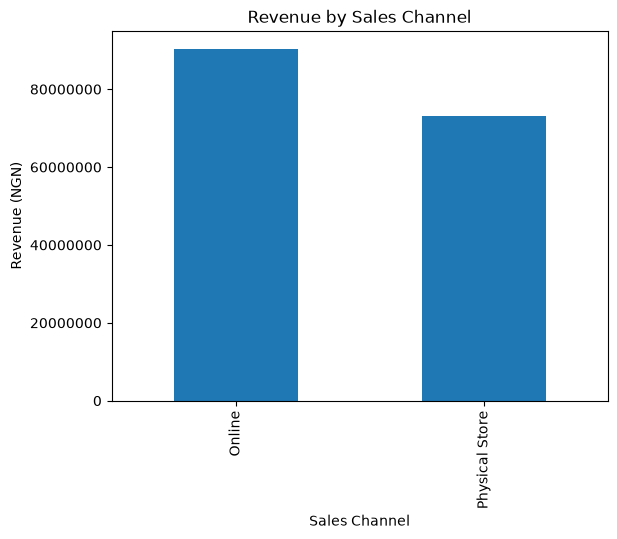

In [72]:
dataset.groupby("sales_channel")["net_sales"].sum().plot(kind="bar")

plt.title("Revenue by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Revenue (NGN)")
plt.ticklabel_format(style="plain", axis="y")
plt.show()

In [73]:
# Which 10 products generate the highest revenue?



dataset.groupby("product_name")["net_sales"].sum().nlargest(10)

product_name
Running Sneakers    15248100.0
Summer Dress        13255200.0
Evening Gown        12846600.0
Ankle Boots         12275200.0
Hoodie               8348750.0
Leather Sandals      8329625.0
Canvas Trainers      8153800.0
Wrist Watch          7811650.0
Denim Jeans          7777125.0
Blazer               7416000.0
Name: net_sales, dtype: float64

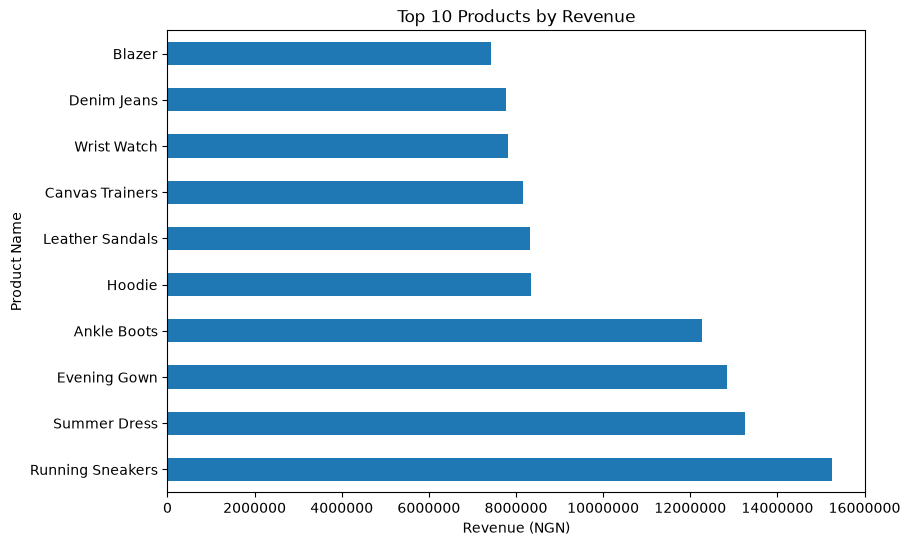

In [76]:
dataset.groupby("product_name")["net_sales"].sum().nlargest(10).plot(kind="barh", figsize=(9, 6))

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (NGN)")
plt.ylabel("Product Name")
plt.ticklabel_format(style="plain", axis="x")
plt.show()

In [77]:
# Which product categories generate the highest revenue in each season?


heatmap_data = dataset.pivot_table(
    values="net_sales",
    index="category",
    columns="season",
    aggfunc="sum"
)

heatmap_data

season,Dry,Rainy
category,,
Accessories,15075700.0,18491525.0
Clothing,31681625.0,44303425.0
Footwear,22327450.0,31724850.0


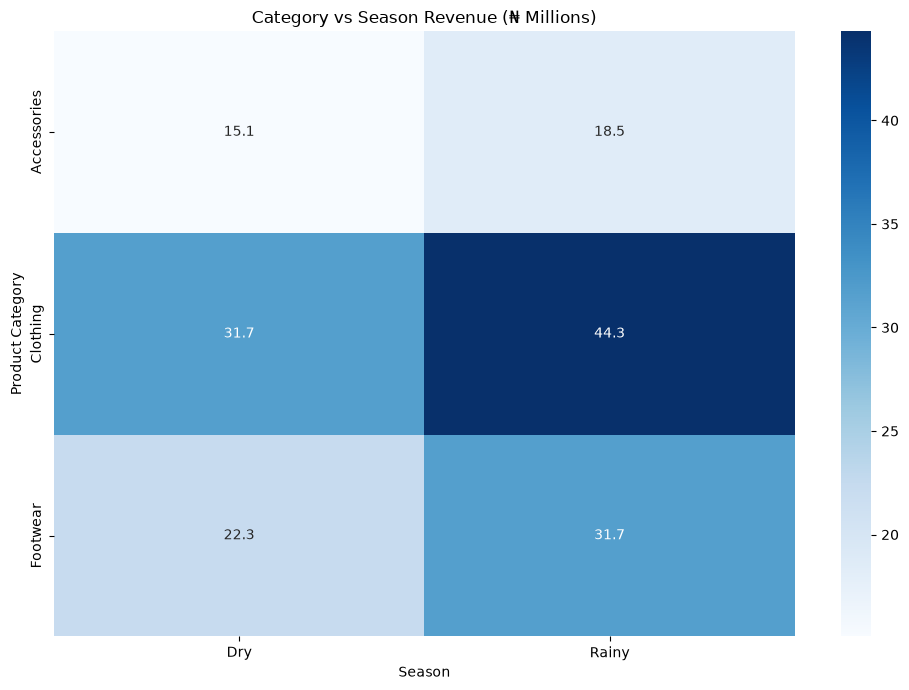

In [80]:
import seaborn as sns

plt.figure(figsize=(10, 7))


sns.heatmap(heatmap_data / 1000000, annot=True, fmt=".1f", cmap="Blues")

plt.title("Category vs Season Revenue (₦ Millions)")
plt.xlabel("Season")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

In [81]:
# Which regions generate the highest revenue?


dataset.groupby("region")["net_sales"].sum().sort_values(ascending=False)

region
Lagos            57012625.0
Abuja            36615725.0
Port Harcourt    25728125.0
Ibadan           18005150.0
Kano             14774250.0
Enugu            11333725.0
Unknown            134975.0
Name: net_sales, dtype: float64

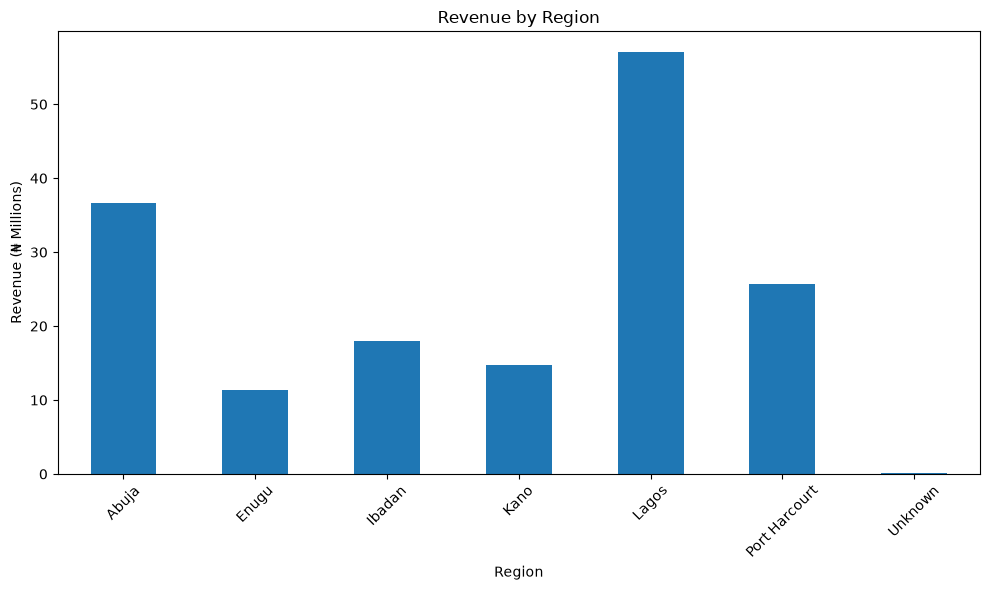

In [82]:
regional = dataset.groupby("region")["net_sales"].sum()

(regional / 1000000).plot(kind="bar", figsize=(10, 6))

plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue (₦ Millions)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

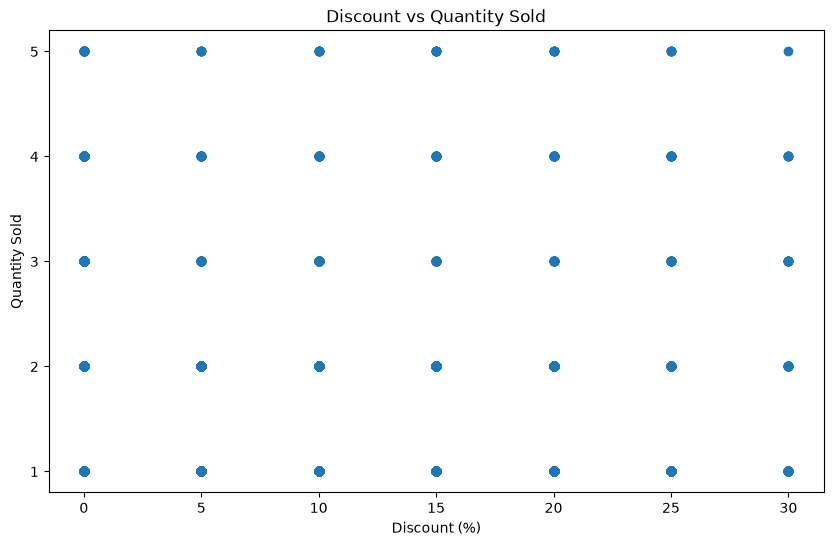

In [84]:
# Do higher discounts lead to more products being purchased?


plt.figure(figsize=(10, 6))

plt.scatter(dataset["discount"] * 100, dataset["quantity"])

plt.title("Discount vs Quantity Sold")
plt.xlabel("Discount (%)")
plt.ylabel("Quantity Sold")
plt.yticks([1, 2, 3, 4, 5])
plt.show()

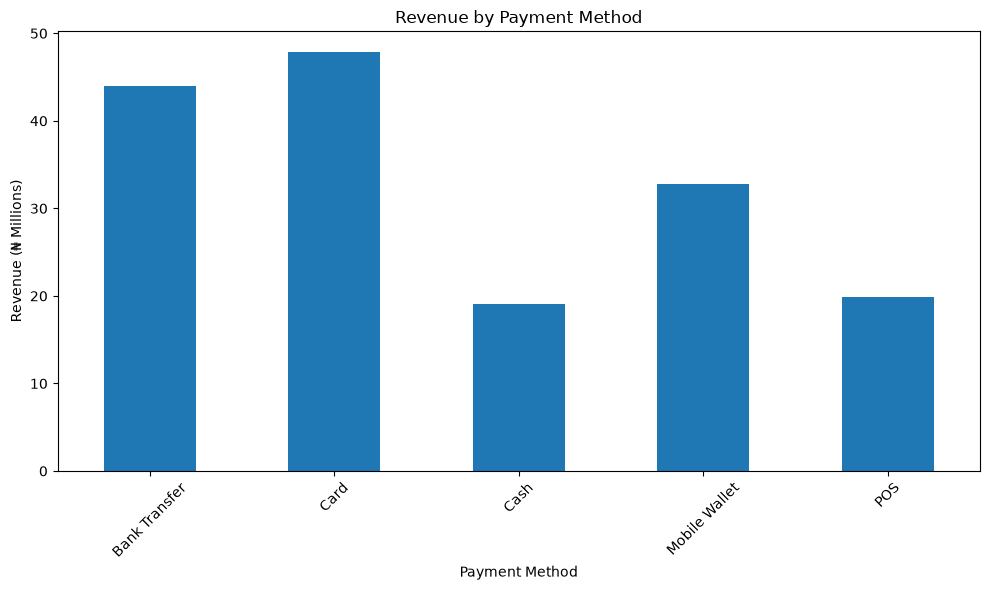

In [85]:
# Which payment method generates the highest revenue?


payment = dataset.groupby("payment_method")["net_sales"].sum()

(payment / 1000000).plot(kind="bar", figsize=(10, 6))

plt.title("Revenue by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Revenue (₦ Millions)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

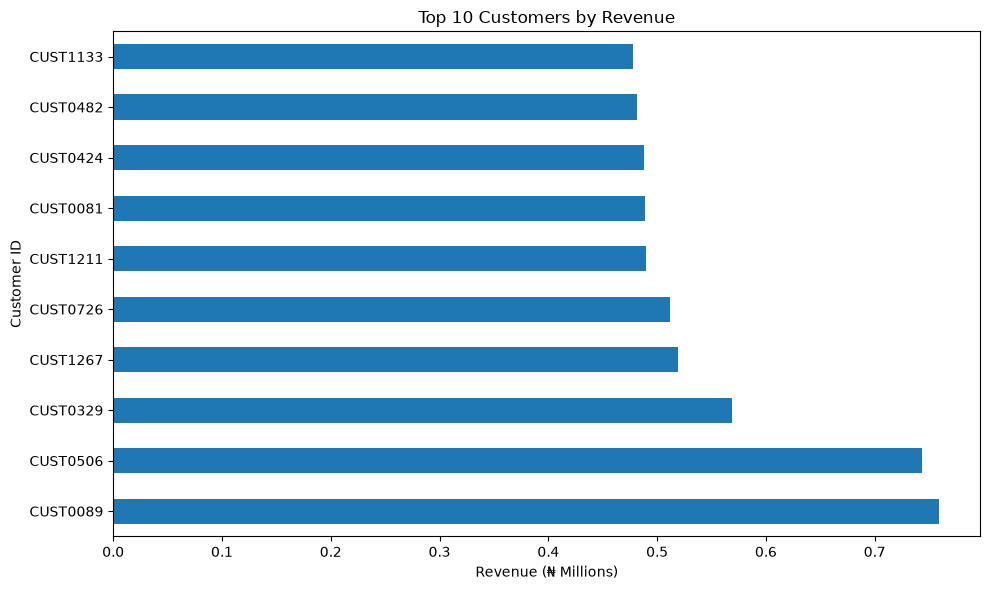

In [86]:
# Which customers contribute the most revenue to the fashion company?



customers = dataset.groupby("customer_id")["net_sales"].sum().nlargest(10)

(customers / 1000000).plot(kind="barh", figsize=(10, 6))

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Revenue (₦ Millions)")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()

## Business Insights and Recommendations

### 1. Product Category Performance

**Business Question:** Which product category generates the highest revenue?

**Finding:** Clothing generated the highest revenue of ₦75,985,050, followed by Footwear with ₦54,052,300 and Accessories with ₦33,567,225.

**Business Insight:** Clothing is the company's strongest category in terms of revenue.

**Recommendation:** The company should maintain sufficient clothing inventory and introduce targeted promotions to improve sales in other categories.


### 2. Monthly Sales Trends

**Business Question:** How does sales revenue change from month to month?

**Finding:** January 2024 recorded the highest monthly revenue of ₦8,251,425, while June 2025 recorded the lowest revenue of ₦4,894,250.

**Business Insight:** Sales revenue fluctuated across the months, showing that some periods performed better than others.

**Recommendation:** The company should investigate the reasons for lower sales in certain months and introduce targeted marketing campaigns to improve performance. It should also prepare sufficient inventory during periods of higher demand.

In [90]:
monthly = dataset.groupby(dataset["order_date"].dt.to_period("M"))["net_sales"].sum()

print("Highest:", monthly.idxmax(), monthly.max())
print("Lowest:", monthly.idxmin(), monthly.min())

Highest: 2024-01 8251425.0
Lowest: 2025-06 4894250.0


### 3. Seasonal Sales Performance

**Business Question:** Which season generates the highest revenue?

**Finding:** The Rainy season generated ₦94,519,800, while the Dry season generated ₦69,084,775.

**Business Insight:** Although the Rainy season generated more total revenue, it covers more months. When comparing average monthly revenue, the Dry season performed slightly better.

**Recommendation:** The company should maintain sufficient inventory throughout both seasons and use seasonal sales trends to plan marketing campaigns and stock levels.

In [91]:
seasonal = dataset.groupby("season")["net_sales"].sum()

print(seasonal)

season
Dry      69084775.0
Rainy    94519800.0
Name: net_sales, dtype: float64


### 4. Online vs Physical Store Sales

**Business Question:** Which sales channel generates the highest revenue?

**Finding:** Online sales generated ₦90,396,500, while Physical Store sales generated ₦73,208,075.

**Business Insight:** The online sales channel contributed more revenue than physical stores, making it the company's stronger sales channel during the period analyzed.

**Recommendation:** The company should invest more in digital marketing, improve its online shopping experience, and maintain good customer service in physical stores.

In [92]:
channel = dataset.groupby("sales_channel")["net_sales"].sum()

print(channel)

sales_channel
Online            90396500.0
Physical Store    73208075.0
Name: net_sales, dtype: float64


### 5. Top Products by Revenue

**Business Question:** Which products generate the highest revenue?

**Finding:** Running Sneakers generated the highest revenue of ₦15,248,100, followed by Summer Dress with ₦13,255,200 and Evening Gown with ₦12,846,600.

**Business Insight:** These three products are the company's strongest revenue-generating products during the period analyzed.

**Recommendation:** The company should maintain sufficient stock of these popular products, monitor their demand, and promote them through targeted marketing campaigns.

In [93]:
top_products = dataset.groupby("product_name")["net_sales"].sum()

print(top_products.nlargest(10))

product_name
Running Sneakers    15248100.0
Summer Dress        13255200.0
Evening Gown        12846600.0
Ankle Boots         12275200.0
Hoodie               8348750.0
Leather Sandals      8329625.0
Canvas Trainers      8153800.0
Wrist Watch          7811650.0
Denim Jeans          7777125.0
Blazer               7416000.0
Name: net_sales, dtype: float64


## Conclusion

The analysis showed that Clothing generated the highest revenue, Online sales performed better than Physical Store sales, and Running Sneakers were the top revenue-generating product.

The findings can help the company improve inventory planning, marketing strategies, and customer satisfaction.